In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
from utils.load_splits import load_splits
from utils.eval_tools import compare_models, bootstrap_compare, compare_by_segment, plot_comparison, plot_segments, plot_bootstrap, plot_tradeoff
from models.popularity import PopularityModel
from models.cat_pop import CategoryPopularityModel
from models.itemCF import ItemCFModel

In [3]:
train_raw, val_raw, test_raw=load_splits(
    train_path="../../data/split/train.parquet",
    val_path="../../data/split/val.parquet",
    test_path="../../data/split/test.parquet",
)

train = train_raw[train_raw['sales_channel_id']==2]
val = val_raw[val_raw['sales_channel_id']==2]
test = test_raw[test_raw['sales_channel_id']==2]

### **MODELS INIT & DESCRIPTION & EVALUATION**

In [4]:
articles=pd.read_parquet("../../data/cleaned_art.parquet")
types=articles.set_index("article_id")["product_type_no"] #types = product type

In [5]:
# models
models = {
    "pop_discovery": PopularityModel(exclude_seen=True), # baseline
    "cat_pop": CategoryPopularityModel(types), # baseline
    "cf_plain": ItemCFModel(types, allow_same_category=True),
    "cf_complement": ItemCFModel(types, allow_same_category=False),
    "cf_strict": ItemCFModel(types, exclude_owned_categories=True),
    "cf_lastday": ItemCFModel(types, allow_same_category=True, source="last_day"),
}

In [6]:
summary, per_user = compare_models(models, train, val, baseline="pop_discovery", problem="discovery", k=12)

Setup: user_group=warm, truth_mode=novel -> 7,358 users, 27,569 relevant purchases
        14.9% of relevant purchases are articles never seen in history (no history-based model can reach them)
Evaluating pop_discovery ...
Evaluating cat_pop ...
Evaluating cf_plain ...
Evaluating cf_complement ...
Evaluating cf_strict ...
Evaluating cf_lastday ...


In [8]:
# bootstrap CI - paired CI
ci_df, paired_df=bootstrap_compare(per_user,baseline="cat_pop", k=12)

In [9]:
summary.to_csv("results/model_comparison_v1.csv")
paired_df.to_csv("results/paired_ci_df_v1.csv")

### **PLOTTING**

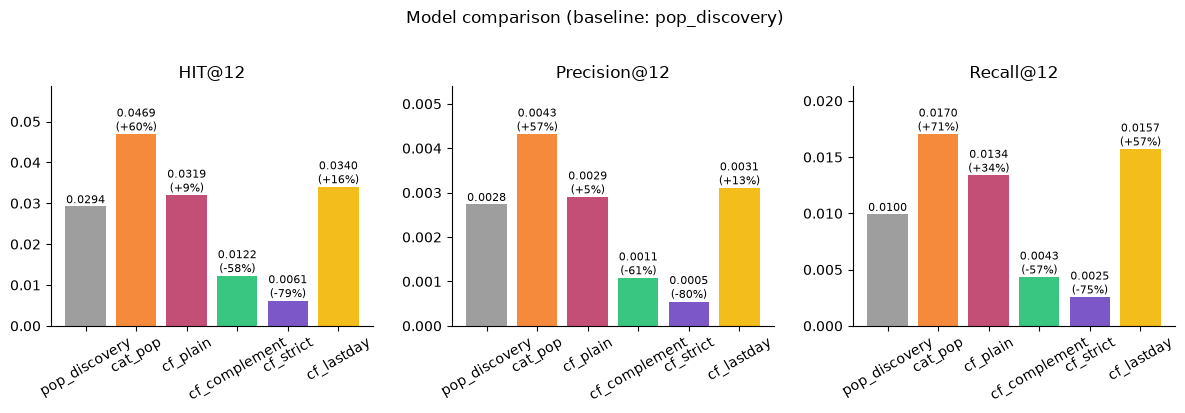

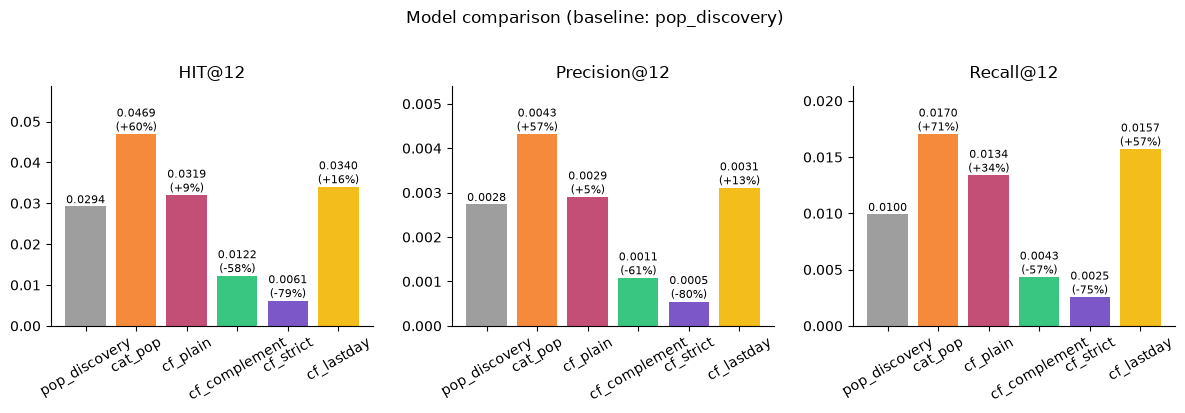

In [13]:
# plotting the summary df
plot_comparison(summary, baseline="pop_discovery", k=12)

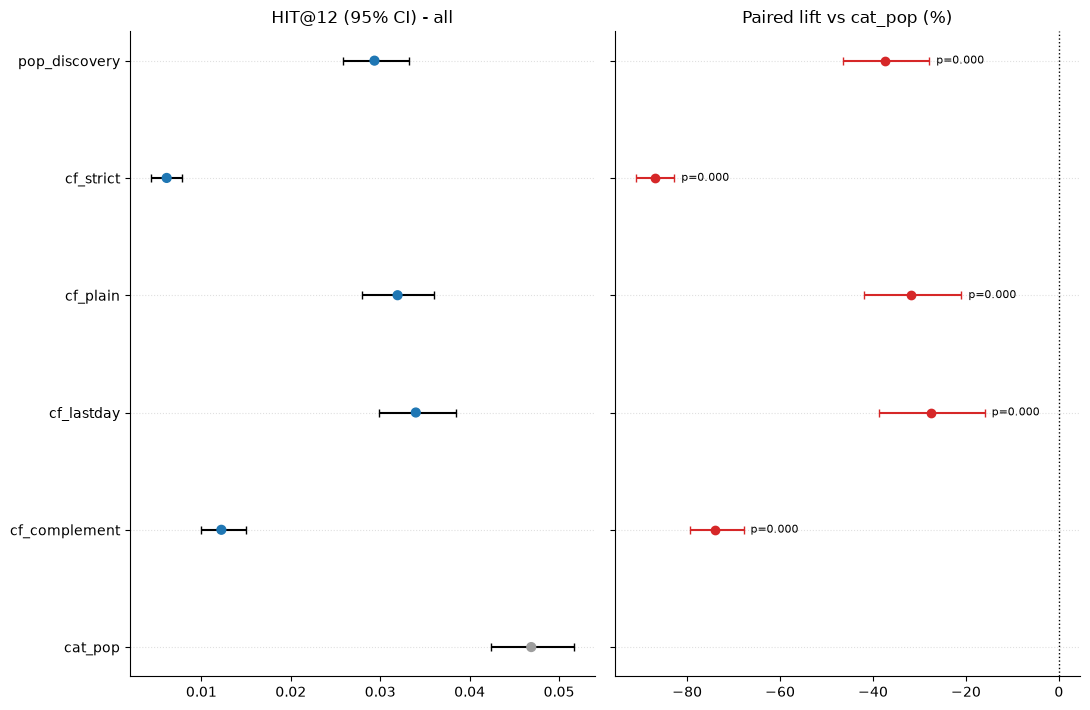

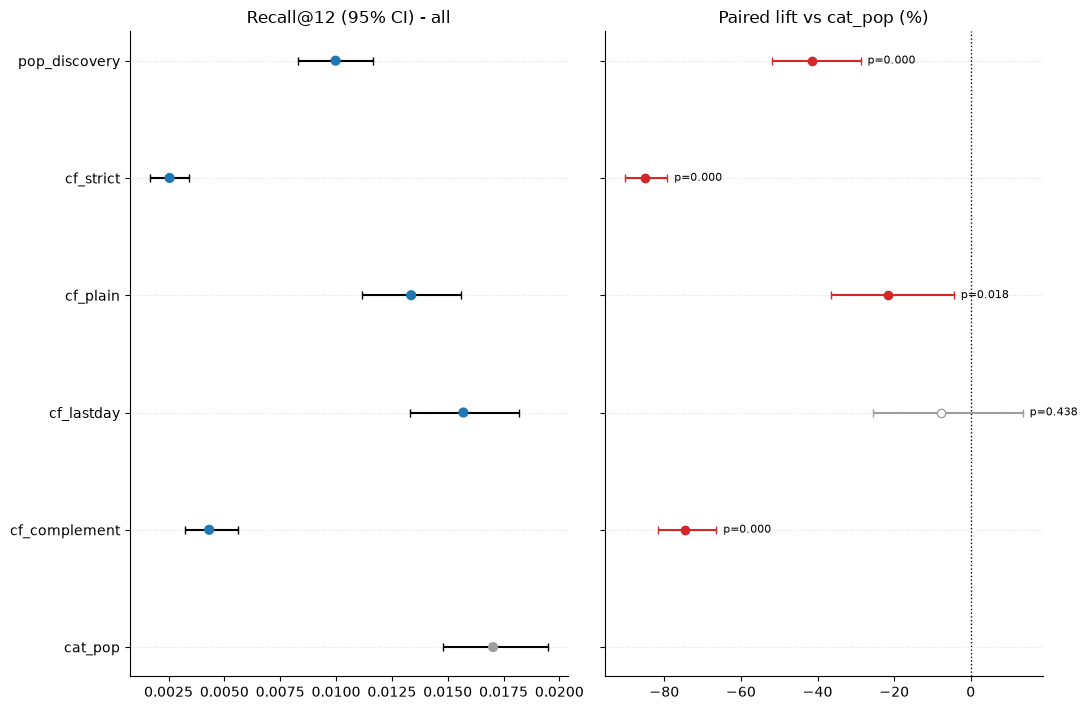

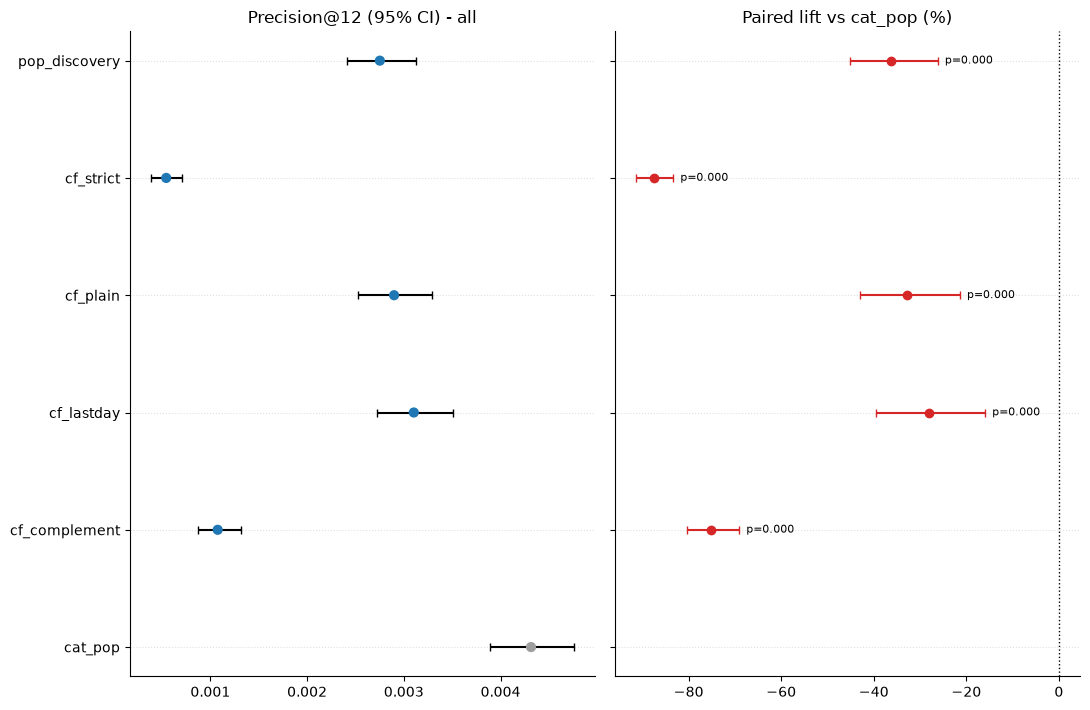

In [17]:
# plotting the bootstrap
metrics=["HIT", "Recall", "Precision"]
for metric in metrics:
    plot_bootstrap(ci_df,paired_df,baseline="cat_pop", metric=metric)

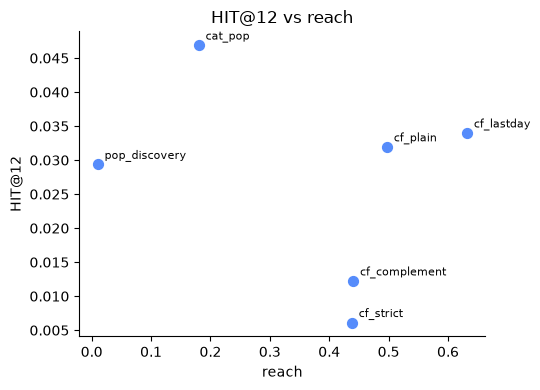

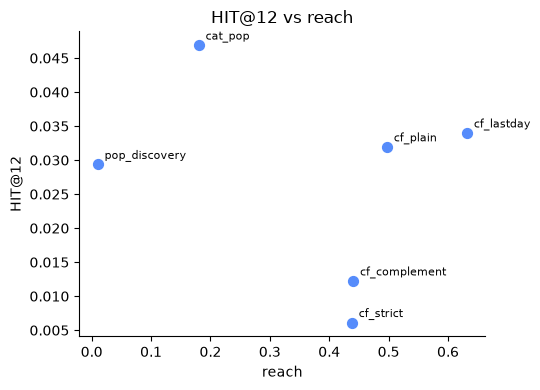

In [33]:
plot_tradeoff(summary, x="reach")

**Conclusion**: Not so many significant signals ⇒ the category_popularity is still a baseline to beat in terms of "accuracy" metrics, but ItemCF models show great improvement in terms of "reach", "head share" and "catalog coverage" → user discovery behavior is still found.

Also, `cf_lastday` seems to perform slightly better than other variants (maybe due to the `recent` signal) => focus on `cf_lastday` and `cat_pop` to discover more insights from these two

=> Bootstrap might be a bit poor as the dataset is sparse and hit% is also sparse as hell -> so the difference might be really hard to differentiate whether it's solid or not -> but to recompute everything is expensive ⇒ **LIMITATIONS & FUTURE WORK**

**what to do next:**
- EDA & Result analysis: main purpose → why the failure & how to improve?
- Plans to have better models - but maybe not in terms of statistics

### **EDA & RESULT ANALYSIS**
Questions to answer:

In [19]:
from utils.eval_tools import build_truth

truth = build_truth(val, train, user_group="warm", truth_mode="novel")   # same hits as problem 3
art = articles.set_index("article_id")
owned = train[["customer_id", "article_id"]].drop_duplicates()
for col in ["product_type_no", "product_code"]:
    owned[col] = owned["article_id"].map(art[col])

def owned_share(pairs, col):
    """Share of (customer, article) pairs whose `col` the customer already bought in train."""
    pairs = pairs.assign(**{col: pairs["article_id"].map(art[col])})
    key = owned[["customer_id", col]].dropna().drop_duplicates()
    merged = pairs.merge(key, on=["customer_id", col], how="left", indicator=True)
    return (merged["_merge"] == "both").mean()

In [21]:
#E1 -
h = per_user.pivot(index="customer_id", columns="model", values="HIT@12")
cat_hit, cf_hit = h["cat_pop"] > 0, h["cf_lastday"] > 0
print(pd.crosstab(cat_hit, cf_hit, rownames=["cat_pop hit"], colnames=["cf_lastday hit"]))

both, only_cat, only_cf = (cat_hit & cf_hit).sum(), (cat_hit & ~cf_hit).sum(), (~cat_hit & cf_hit).sum()
chance = cat_hit.mean() * cf_hit.mean() * len(h)
print(f"hit by both = {both} (expected by pure chance: {chance:.1f})")
print(f"hit by either = {both + only_cat + only_cf} vs cat_pop alone = {cat_hit.sum()}")

cf_lastday hit  False  True 
cat_pop hit                 
False            6788    225
True              320     25
hit by both = 25 (expected by pure chance: 11.7)
hit by either = 570 vs cat_pop alone = 345


In [22]:
for col in ["product_type_no", "product_code"]:
    print(f"{col}: {owned_share(truth, col):.1%} of new purchases are in a {col} the user already bought")

product_type_no: 67.3% of new purchases are in a product_type_no the user already bought
product_code: 4.7% of new purchases are in a product_code the user already bought


In [24]:
# E3
users = truth["customer_id"].unique()
profile = {}
for name in ["cat_pop", "cf_plain", "cf_lastday", "cf_complement", "cf_strict"]:
    recs = models[name].recommend(users=users, k=12)[["customer_id", "article_id"]]
    profile[name] = {col: owned_share(recs, col) for col in ["product_type_no", "product_code"]}
profile["TRUTH (real purchases)"] = {col: owned_share(truth, col) for col in ["product_type_no", "product_code"]}
pd.DataFrame(profile).T.round(3)

,product_type_no,product_code
cat_pop,1.000,0.051
cf_plain,0.872,0.507
cf_lastday,0.769,0.283
cf_complement,0.568,0.050
cf_strict,0.021,0.007
TRUTH (real purchases),0.673,0.047


In [25]:
#E4: long-tail trend
pct = train["article_id"].value_counts().rank(ascending=False, pct=True)   # small = best seller
tier = pd.cut(pct, [0, .01, .10, .50, 1.0], labels=["top 1%", "1-10%", "10-50%", "bottom 50%"])
order = ["top 1%", "1-10%", "10-50%", "bottom 50%", "unseen"]
def tier_of(article_ids):
    return article_ids.map(tier).astype(object).fillna("unseen")

shares = {}
for name in ["cat_pop", "cf_plain", "cf_lastday"]:
    recs = models[name].recommend(users=users, k=12)
    hits = recs.merge(truth, on=["customer_id", "article_id"])             # recommended AND bought
    shares[name] = tier_of(hits["article_id"]).value_counts(normalize=True)
shares["TRUTH"] = tier_of(truth["article_id"]).value_counts(normalize=True)
pd.DataFrame(shares).reindex(order).fillna(0).round(3)

,cat_pop,cf_plain,cf_lastday,TRUTH
article_id,,,,
top 1%,0.457,0.504,0.237,0.102
1-10%,0.213,0.246,0.314,0.172
10-50%,0.325,0.238,0.431,0.381
bottom 50%,0.005,0.012,0.018,0.196
unseen,0.000,0.000,0.000,0.149


In [27]:
# B8 - Testing whether the recommendations make sense among collaborative filtering
# cf complement: suggest "complement" products
# verdict: more "interesting" recommendations and still makes real sense (if we think only about co-purchase)
name_of, type_of = art["prod_name"], art["product_type_name"]
for u in pd.Series(users).sample(3, random_state=1):
    bought = set(truth.loc[truth["customer_id"] == u, "article_id"])
    print(f"\ncustomer {u}")
    for _, r in models["cf_complement"].score_items(u, k=12).iterrows():
        print(f"  because you bought {name_of[r.because_article_id]:<30} -> {name_of[r.article_id]:<30} "
              f"({type_of[r.article_id]}) {'<- HIT' if r.article_id in bought else ''}")


customer 12453
  because you bought Lina Boilersuit                -> Shorts Cheapo                  (Shorts) 
  because you bought Control Top 30 den 1p Tights   -> Support 40 den 1p Tights       (Underwear Tights) 
  because you bought Emma shiny stripe              -> ANDERS LS POLO                 (Sweater) 
  because you bought Khloe beandeau top             -> Chelsea biker                  (Jacket) 
  because you bought Therese tee                    -> Jade HW Skinny Denim TRS       (Trousers) 
  because you bought Emma shiny stripe              -> Banks                          (Hoodie) 
  because you bought Therese tee                    -> Tilda tank                     (Vest top) 
  because you bought Lina Boilersuit                -> Samantha                       (Sweater) 
  because you bought Emma shiny stripe              -> Mocca                          (Dress) 
  because you bought Lina Boilersuit                -> Tina Fur                       (Jacket) 
  because

In [30]:
# B8 - Testing whether the recommendations make sense among collaborative filtering
# cf lastday:
# verdict: not user discovery much actually - as it recommends the same item within category -> then it is quite similar to cat_pop
name_of, type_of = art["prod_name"], art["product_type_name"]
for u in pd.Series(users).sample(3, random_state=2):
    bought = set(truth.loc[truth["customer_id"] == u, "article_id"])
    print(f"\ncustomer {u}")
    for _, r in models["cf_lastday"].score_items(u, k=12).iterrows():
        print(f"  because you bought {name_of[r.because_article_id]:<30} -> {name_of[r.article_id]:<30} "
              f"({type_of[r.article_id]}) {'<- HIT' if r.article_id in bought else ''}")


customer 22732
  because you bought Lilly Tank (1)                 -> Lilly Tank (1)                 (Top) 
  because you bought Lilly Tank (1)                 -> Lilly Tank (1)                 (Top) 
  because you bought Lilly Tank (1)                 -> Lilly Tank (1)                 (Top) 
  because you bought Lilly Tank (1)                 -> Lilly Tank (1)                 (Top) 
  because you bought Lilly Tank (1)                 -> Noelia Rib Tank                (Vest top) 
  because you bought Lilly Tank (1)                 -> Ella soft bag                  (Bag) 
  because you bought Lilly Tank (1)                 -> Belinda HW linen Trs           (Trousers) 
  because you bought Lilly Tank (1)                 -> Dag shoulder tote              (Bag) 
  because you bought Lilly Tank (1)                 -> Copenhagen Fur                 (Jacket) 
  because you bought Lilly Tank (1)                 -> Knot aliceband                 (Hair/alice band) 
  because you bought Lilly Ta

In [31]:
# B8 - Testing whether the recommendations make sense among collaborative filtering
# cf plain:
# verdict: not user discovery
name_of, type_of = art["prod_name"], art["product_type_name"]
for u in pd.Series(users).sample(3, random_state=3):
    bought = set(truth.loc[truth["customer_id"] == u, "article_id"])
    print(f"\ncustomer {u}")
    for _, r in models["cf_plain"].score_items(u, k=12).iterrows():
        print(f"  because you bought {name_of[r.because_article_id]:<30} -> {name_of[r.article_id]:<30} "
              f"({type_of[r.article_id]}) {'<- HIT' if r.article_id in bought else ''}")


customer 97265
  because you bought C Antibes Triangle             -> C Antibes Tie Tanga            (Swimwear bottom) 
  because you bought Flirty Hope necklace           -> Flirty Maria ring pk           (Ring) 
  because you bought Flirty Loa Hoop                -> Class Limon hoop               (Earring) 
  because you bought Sandra squared                 -> Daniela Sunglasses             (Sunglasses) 
  because you bought Bird                           -> Bird                           (T-shirt) 
  because you bought Berlin cat sunglasses          -> Berlin cat sunglasses          (Sunglasses) 
  because you bought Kattis cat sunglasses          -> Gertrud sunglasses             (Sunglasses) 
  because you bought Sandra squared                 -> Wendy Bodycon Dress            (Dress) 
  because you bought Kattis cat sunglasses          -> Kattis cat sunglasses          (Sunglasses) 
  because you bought Berlin cat sunglasses          -> Alessa cat sunglasses          (Sunglasse

### **Key finding:**
* ,,

### **Action:**
* A blend model, excluding owned product code with reciprocal ranking (MVP)
* Content features feeding